# Knowledge Distillation Experiment: Image Classification (MNIST)

## Experiment Goals:
1. Train a large CNN teacher on MNIST
2. Train a small CNN student using distillation
3. Compare with a baseline student (no distillation)
4. Analyze performance vs model size tradeoff

## Setup and Dependencies

In [36]:
# setup: using keras/tensorflow instead of pytorch (pytorch has compatibility issues)
# uncomment below if tensorflow not installed
#!pip install tensorflow

import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import tensorflow as tf
import time

# set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"tensorflow version: {tf.__version__}")
print(f"keras version: {keras.__version__}")

tensorflow version: 2.18.0
keras version: 3.6.0


## Load MNIST Dataset

downloading MNIST with keras...
training samples: 60000
test samples: 10000
training data shape: (60000, 28, 28, 1)
test data shape: (10000, 28, 28, 1)
training samples: 60000
test samples: 10000
training data shape: (60000, 28, 28, 1)
test data shape: (10000, 28, 28, 1)


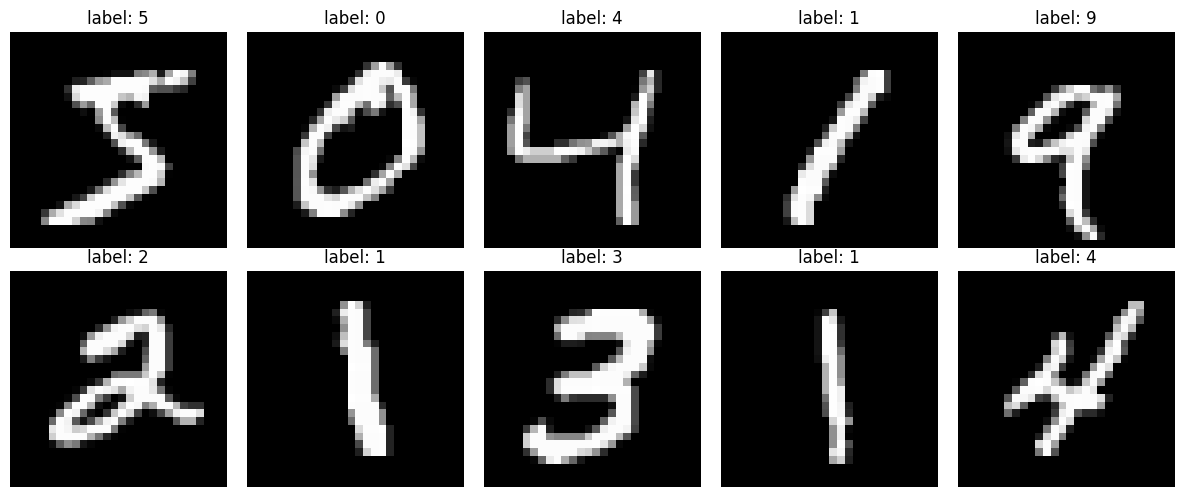

In [37]:
# download MNIST dataset using keras
print("downloading MNIST with keras...")

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# normalize the data to [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# add channel dimension (keras uses channels_last format)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print(f"training samples: {len(x_train)}")
print(f"test samples: {len(x_test)}")
print(f"training data shape: {x_train.shape}")
print(f"test data shape: {x_test.shape}")

# plot some samples
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img = x_train[i].squeeze()
    label = y_train[i]
    
    ax.imshow(img, cmap='gray')
    ax.set_title(f'label: {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Define Teacher and Student Models

In [38]:
# define teacher model (large CNN with more parameters)
def create_teacher_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(128, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(256, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Flatten(),
        keras.layers.Dense(512, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(10, activation='softmax'),
    ])
    return model

teacher = create_teacher_model()
teacher.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,683,722 (6.42 MB)

 Trainable params: 1,683,722 (6.42 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# define student model (smaller CNN with fewer parameters)
def create_student_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation='softmax'),
    ])
    return model

student = create_student_model()
student.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       200,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 206,922 (808.29 KB)

 Trainable params: 206,922 (808.29 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# compare model sizes
teacher_params = teacher.count_params()
student_params = student.count_params()

print("model architecture comparison:")
print(f"teacher parameters: {teacher_params:,}")
print(f"student parameters: {student_params:,}")
print(f"compression ratio: {teacher_params/student_params:.1f}x")
print(f"size reduction: {(1-student_params/teacher_params)*100:.1f}%")

model architecture comparison:
teacher parameters: 1,683,722
student parameters: 206,922
compression ratio: 8.1x
size reduction: 87.7%


## Training Functions

In [41]:
# define distillation loss function
class DistillationLoss(keras.losses.Loss):
    def __init__(self, temperature=4.0, alpha=0.7):
        super().__init__()
        self.temperature = temperature
        self.alpha = alpha
        
    def call(self, y_true, y_pred, teacher_pred):
        # student loss (regular cross-entropy)
        student_loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        
        # distillation loss (kl divergence between soft predictions)
        teacher_soft = tf.nn.softmax(teacher_pred / self.temperature)
        student_soft = tf.nn.softmax(y_pred / self.temperature)
        distill_loss = tf.reduce_mean(
            tf.reduce_sum(teacher_soft * tf.math.log(teacher_soft / (student_soft + 1e-10)), axis=1)) * (self.temperature ** 2)
        
        # combine losses
        return self.alpha * distill_loss + (1 - self.alpha) * student_loss

print("distillation loss function defined")

distillation loss function defined


## Train Teacher Model

In [42]:
# no need for data format conversion since we're using keras throughout
batch_size = 128
print(f"batch size: {batch_size}")

batch size: 128


In [43]:
# train teacher model
print("training teacher model...")

teacher = create_teacher_model()
teacher.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'])

history_teacher = teacher.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=batch_size,
    verbose=1)

teacher_losses = history_teacher.history['loss']
teacher_accs = [acc * 100 for acc in history_teacher.history['val_accuracy']]

print(f"\nfinal teacher accuracy: {teacher_accs[-1]:.2f}%")

training teacher model...
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.8012 - loss: 0.5786 - val_accuracy: 0.9862 - val_loss: 0.0420
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.8012 - loss: 0.5786 - val_accuracy: 0.9862 - val_loss: 0.0420
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9826 - loss: 0.0608 - val_accuracy: 0.9887 - val_loss: 0.0363
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9826 - loss: 0.0608 - val_accuracy: 0.9887 - val_loss: 0.0363
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - accuracy: 0.9895 - loss: 0.0387 - val_accuracy: 0.9894 - val_loss: 0.0341
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - accuracy: 0.9895 - loss: 0.0387 - val_accuracy: 0.9894 - val_loss: 0.0341
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 59ms/step - accuracy: 0.9907 - loss: 0.0326 - val_accuracy: 0.9915 - val_loss: 0.0316
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 59ms/step - accuracy

## train student with distillation

In [44]:
# train student with distillation
print("training student with knowledge distillation")

# create custom training loop for distillation
student_distilled = create_student_model()
optimizer = keras.optimizers.Adam(learning_rate=0.001)

temperature = 4.0
alpha = 0.7

distill_losses = []
distill_accs = []

epochs = 10
steps_per_epoch = len(x_train) // batch_size

for epoch in range(epochs):
    print(f"\nepoch {epoch+1}/{epochs}")
    epoch_loss = 0
    epoch_acc = 0
    
    # shuffle training data
    indices = np.random.permutation(len(x_train))
    x_train_shuffled = x_train[indices]
    y_train_shuffled = y_train[indices]
    
    for step in range(steps_per_epoch):
        start_idx = step * batch_size
        end_idx = start_idx + batch_size
        
        x_batch = x_train_shuffled[start_idx:end_idx]
        y_batch = y_train_shuffled[start_idx:end_idx]
        
        with tf.GradientTape() as tape:
            # get teacher predictions (no training)
            teacher_logits = teacher(x_batch, training=False)
            
            # get student predictions
            student_logits = student_distilled(x_batch, training=True)
            
            # calculate distillation loss
            teacher_soft = tf.nn.softmax(teacher_logits / temperature)
            student_soft = tf.nn.softmax(student_logits / temperature)
            
            distill_loss = tf.reduce_mean(tf.reduce_sum(teacher_soft * tf.math.log(teacher_soft / (student_soft + 1e-10)), axis=1)) * (temperature ** 2)
            
            student_loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(y_batch, student_logits))
            loss = alpha * distill_loss + (1 - alpha) * student_loss
        
        # update student weights
        gradients = tape.gradient(loss, student_distilled.trainable_variables)
        optimizer.apply_gradients(zip(gradients, student_distilled.trainable_variables))
        
        epoch_loss += loss.numpy()
        
        # calculate accuracy
        predictions = tf.argmax(student_logits, axis=1)
        epoch_acc += tf.reduce_mean(tf.cast(tf.equal(predictions, y_batch), tf.float32)).numpy()
    
    avg_loss = epoch_loss / steps_per_epoch
    avg_acc = epoch_acc / steps_per_epoch
    
    # evaluate on test set
    test_logits = student_distilled(x_test, training=False)
    test_preds = tf.argmax(test_logits, axis=1)
    test_acc = tf.reduce_mean(tf.cast(tf.equal(test_preds, y_test), tf.float32)).numpy() * 100
    
    distill_losses.append(avg_loss)
    distill_accs.append(test_acc)
    
    print(f"loss: {avg_loss:.4f}, train acc: {avg_acc*100:.2f}%, test acc: {test_acc:.2f}%")

print(f"\nfinal distilled student accuracy: {distill_accs[-1]:.2f}%")

training student with knowledge distillation

epoch 1/10
loss: 0.0910, train acc: 91.57%, test acc: 97.82%

epoch 2/10
loss: 0.0910, train acc: 91.57%, test acc: 97.82%

epoch 2/10
loss: 0.0256, train acc: 97.59%, test acc: 98.57%

epoch 3/10
loss: 0.0256, train acc: 97.59%, test acc: 98.57%

epoch 3/10
loss: 0.0190, train acc: 98.18%, test acc: 98.77%

epoch 4/10
loss: 0.0190, train acc: 98.18%, test acc: 98.77%

epoch 4/10
loss: 0.0152, train acc: 98.51%, test acc: 98.64%

epoch 5/10
loss: 0.0152, train acc: 98.51%, test acc: 98.64%

epoch 5/10
loss: 0.0122, train acc: 98.83%, test acc: 98.94%

epoch 6/10
loss: 0.0122, train acc: 98.83%, test acc: 98.94%

epoch 6/10
loss: 0.0106, train acc: 98.93%, test acc: 99.11%

epoch 7/10
loss: 0.0106, train acc: 98.93%, test acc: 99.11%

epoch 7/10
loss: 0.0096, train acc: 99.06%, test acc: 99.02%

epoch 8/10
loss: 0.0096, train acc: 99.06%, test acc: 99.02%

epoch 8/10
loss: 0.0082, train acc: 99.18%, test acc: 99.27%

epoch 9/10
loss: 0.0082,

##  Train Baseline Student (No Distillation)

In [45]:
# train baseline student (no distillation)
print("training baseline student (no distillation)...")

student_baseline = create_student_model()
student_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'])

history_baseline = student_baseline.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=batch_size,
    verbose=1)

baseline_losses = history_baseline.history['loss']
baseline_accs = [acc * 100 for acc in history_baseline.history['val_accuracy']]

print(f"\nfinal baseline student accuracy: {baseline_accs[-1]:.2f}%")

training baseline student (no distillation)...
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8246 - loss: 0.5771 - val_accuracy: 0.9805 - val_loss: 0.0612
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8246 - loss: 0.5771 - val_accuracy: 0.9805 - val_loss: 0.0612
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9759 - loss: 0.0809 - val_accuracy: 0.9849 - val_loss: 0.0460
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9759 - loss: 0.0809 - val_accuracy: 0.9849 - val_loss: 0.0460
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9832 - loss: 0.0569 - val_accuracy: 0.9858 - val_loss: 0.0426
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9832 - loss: 0.0569 - val_accuracy: 0.9858 - val_loss: 0.0426
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9858 - loss: 0.0462 - val_accuracy: 0.9893 - val_loss: 0.0323
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - acc

## Results Comparison

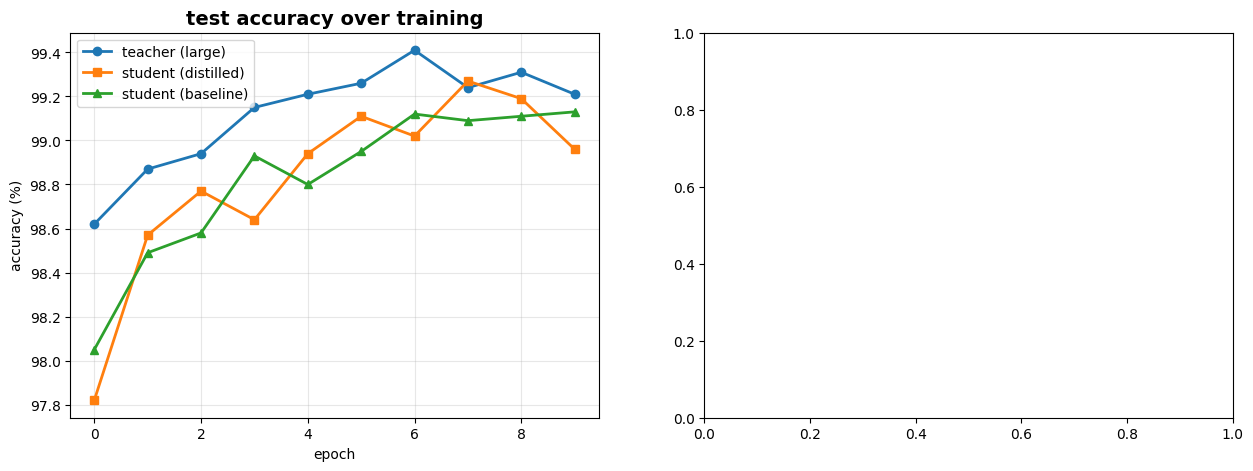

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# plot accuracy comparison
axes[0].plot(teacher_accs, marker='o', label='teacher (large)', linewidth=2)
axes[0].plot(distill_accs, marker='s', label='student (distilled)', linewidth=2)
axes[0].plot(baseline_accs, marker='^', label='student (baseline)', linewidth=2)
axes[0].set_title('test accuracy over training', fontsize=14, fontweight='bold')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('accuracy (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

In [47]:
# loss comparison
axes[1].plot(teacher_losses, marker='o', label='teacher', linewidth=2)
axes[1].plot(distill_losses, marker='s', label='student (distilled)', linewidth=2)
axes[1].plot(baseline_losses, marker='^', label='student (baseline)', linewidth=2)
axes[1].set_title('training loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('distillation_results.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [48]:
# final comparison
print("final results:")
print(f"teacher (large model): {teacher_accs[-1]:.2f}%")
print(f"student with distillation: {distill_accs[-1]:.2f}%")
print(f"student without distillation: {baseline_accs[-1]:.2f}%")

final results:
teacher (large model): 99.21%
student with distillation: 98.96%
student without distillation: 99.13%


In [ ]:
print(f"distillation improvement: +{distill_accs[-1] - baseline_accs[-1]:.2f}%")
print(f"gap to teacher (with distillation): {teacher_accs[-1] - distill_accs[-1]:.2f}%")
print(f"gap to teacher (baseline): {teacher_accs[-1] - baseline_accs[-1]:.2f}%")

print(f"model size reduction: {(1-student_params/teacher_params)*100:.1f}%")
print(f"performance retained: {(distill_accs[-1]/teacher_accs[-1])*100:.1f}%")

distillation improvement: +-0.17%
gap to teacher (with distillation): 0.25%
gap to teacher (baseline): 0.08%

model size reduction: 87.7%
performance retained: 99.7%


## Inference Speed Comparison

In [50]:
# measure inference time
def measure_inference_time(model, x_test, num_batches=50):
    times = []
    
    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = start_idx + batch_size
        
        if end_idx > len(x_test):
            break
            
        x_batch = x_test[start_idx:end_idx]
        
        start_time = time.time()
        _ = model(x_batch, training=False)
        end_time = time.time()
        
        times.append(end_time - start_time)
    
    return np.mean(times) * 1000

teacher_time = measure_inference_time(teacher, x_test)
student_time = measure_inference_time(student_distilled, x_test)

print("\ninference speed comparison:")
print(f"teacher inference time: {teacher_time:.2f} ms/batch")
print(f"student inference time: {student_time:.2f} ms/batch")
print(f"speedup: {teacher_time/student_time:.2f}x faster")
print(f"\nstudent model is {teacher_time/student_time:.1f}x faster with only "
      f"{teacher_accs[-1] - distill_accs[-1]:.2f}% accuracy drop")


inference speed comparison:
teacher inference time: 32.79 ms/batch
student inference time: 8.78 ms/batch
speedup: 3.73x faster

student model is 3.7x faster with only 0.25% accuracy drop


## Visualize Predictions

In [ ]:
# get some test samples for visualization
num_samples = 5
test_images = x_test[:batch_size]
test_labels = y_test[:batch_size]

teacher_preds = tf.argmax(teacher(test_images, training=False), axis=1).numpy()
distilled_preds = tf.argmax(student_distilled(test_images, training=False), axis=1).numpy()
baseline_preds = tf.argmax(student_baseline(test_images, training=False), axis=1).numpy()

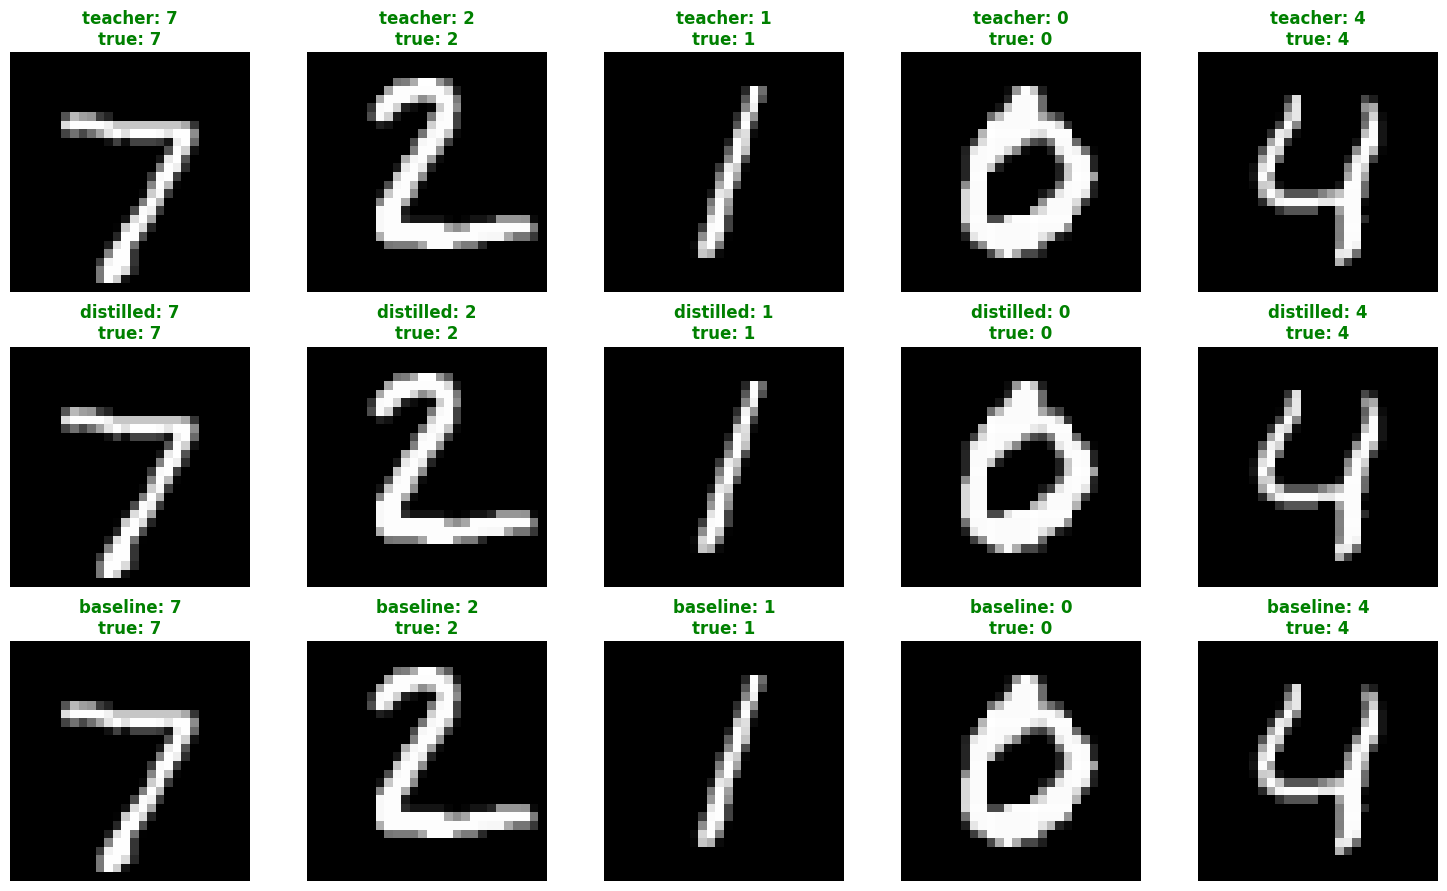

In [52]:
# visualize predictions
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i in range(5):
    img = test_images[i].squeeze()
    true_label = test_labels[i]
    
    # show image in all rows
    for row in range(3):
        axes[row, i].imshow(img, cmap='gray')
        axes[row, i].axis('off')
    
    # teacher prediction
    t_pred = teacher_preds[i]
    color = 'green' if t_pred == true_label else 'red'
    axes[0, i].set_title(f'teacher: {t_pred}\ntrue: {true_label}', color=color, fontweight='bold')
    
    # distilled student prediction
    d_pred = distilled_preds[i]
    color = 'green' if d_pred == true_label else 'red'
    axes[1, i].set_title(f'distilled: {d_pred}\ntrue: {true_label}', color=color, fontweight='bold')
    
    # baseline student prediction
    b_pred = baseline_preds[i]
    color = 'green' if b_pred == true_label else 'red'
    axes[2, i].set_title(f'baseline: {b_pred}\ntrue: {true_label}', color=color, fontweight='bold')

axes[0, 0].set_ylabel('teacher', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('distilled\nstudent', fontsize=12, fontweight='bold')
axes[2, 0].set_ylabel('baseline\nstudent', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('prediction_comparison.png', dpi=150, bbox_inches='tight')
plt.show()